# توکن طلا (XAUT): چقدر قیمت طلا را دنبال می‌کند؟

**آموزشی است و توصیه سرمایه‌گذاری نیست.** این نوت‌بوک چیزی را پیش‌بینی نمی‌کند و پیشنهاد معامله ندارد.

XAUT توکن طلای Tether است؛ طبق اعلام صادرکننده، هر توکن یک اونس طلا را نمایندگی می‌کند. روی صرافی Bybit هم اسپات و هم قرارداد دائمی (perpetual) دارد. چهار سؤال:

1. **تعقیب:** قیمت XAUT چقدر از قیمت جهانی طلا فاصله دارد؟
2. **بازار ۲۴/۷:** آخر هفته که بازار جهانی طلا بسته است، حرکت XAUT چقدر از شکاف دوشنبه خبر می‌دهد؟
3. **پایه (basis):** قرارداد دائمی چقدر از اسپات فاصله دارد؟
4. **فاندینگ:** هزینه نگه‌داشتن قرارداد دائمی چقدر بوده؟

**داده (از آوریل ۲۰۲۵ که XAUT در Bybit شروع شد):** کندل ساعتی اسپات و دائمی و تاریخچه نرخ فاندینگ از Bybit، آتی طلای COMEX (`GC=F`) ساعتی از Yahoo، و اونس روزانه از TGJU. داده در repo ذخیره نیست و نوت‌بوک آن را می‌گیرد.

In [1]:
import json, time, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..") if Path("../scripts/fetch_data.py").exists() else Path(".")  # repo checkout or Colab
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
(ROOT / "images").mkdir(exist_ok=True)
UA = {"User-Agent": "Mozilla/5.0"}
BYBIT = "https://api.bybit.com/v5/market/"
START_MS = 1743465600000  # 2025-04-01

def get(url, tries=4):
    for k in range(tries):
        try:
            data = json.load(urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=60))
            if isinstance(data, dict) and data.get("retCode", 0) != 0:   # Bybit error (for example rate limit)
                raise RuntimeError(f"Bybit: {data.get('retCode')} {data.get('retMsg')}")
            return data
        except Exception:
            if k == tries - 1:
                raise
            time.sleep(2 * (k + 1))

def bybit_klines(category, symbol):
    out, end = [], None
    for _ in range(80):
        url = f"{BYBIT}kline?category={category}&symbol={symbol}&interval=60&limit=1000" + (f"&end={end}" if end else "")
        rows = get(url)["result"]["list"]
        if not rows:
            break
        out += rows
        end = int(rows[-1][0]) - 1
        if len(rows) < 1000 or end < START_MS:
            break
        time.sleep(0.2)
    df = pd.DataFrame(out, columns=["t", "open", "high", "low", "close", "volume", "turnover"]).astype(float)
    df.index = pd.to_datetime(df.pop("t"), unit="ms")
    return df.sort_index()[~df.index.duplicated()]   # index = bar START time (UTC)

def bybit_funding(symbol):
    out, end = [], None
    for _ in range(40):
        url = f"{BYBIT}funding/history?category=linear&symbol={symbol}&limit=200" + (f"&endTime={end}" if end else "")
        rows = get(url)["result"]["list"]
        if not rows:
            break
        out += rows
        end = int(rows[-1]["fundingRateTimestamp"]) - 1
        if len(rows) < 200:
            break
    s = pd.Series({pd.to_datetime(float(r["fundingRateTimestamp"]), unit="ms"): float(r["fundingRate"]) for r in out}).sort_index()
    return s.rename("funding_rate")

def yahoo_hourly(symbol):
    url = f"https://query2.finance.yahoo.com/v8/finance/chart/{symbol}?period1={START_MS // 1000}&period2=4102444800&interval=1h"
    res = get(url)["chart"]["result"][0]
    q = res["indicators"]["quote"][0]
    return pd.DataFrame({"open": q["open"], "close": q["close"]}, index=pd.to_datetime(res["timestamp"], unit="s")).dropna()

def tgju_ons():
    rows = get("https://api.tgju.org/v1/market/indicator/summary-table-data/ons")["data"]
    return pd.Series({pd.Timestamp(r[6].replace("/", "-")): float(r[3].replace(",", "")) for r in rows}).sort_index()

def cached(name, fetch):
    f = DATA / f"{name}.pkl"          # data is not stored in the repository
    if not f.exists():
        fetch().to_pickle(f)
    return pd.read_pickle(f)

spot = cached("xaut_spot_1h", lambda: bybit_klines("spot", "XAUTUSDT"))
perp = cached("xaut_perp_1h", lambda: bybit_klines("linear", "XAUTUSDT"))
funding = cached("xaut_funding", lambda: bybit_funding("XAUTUSDT"))
gc = cached("gc_1h", lambda: yahoo_hourly("GC=F"))
ons = cached("ons_close", tgju_ons)
print(f"spot  {len(spot)} hourly bars {spot.index[0]} .. {spot.index[-1]}")
print(f"perp  {len(perp)} hourly bars {perp.index[0]} .. {perp.index[-1]}")
print(f"funding {len(funding)} settlements, every {(funding.index.to_series().diff().dt.total_seconds() / 3600).median():.0f} h")
print(f"GC=F  {len(gc)} hourly bars")

spot  13305 hourly bars 2025-04-11 10:00:00 .. 2026-10-17 18:00:00
perp  13496 hourly bars 2025-04-03 11:00:00 .. 2026-10-17 18:00:00
funding 3375 settlements, every 4 h
GC=F  8927 hourly bars


## ۱. نقدشوندگی

قبل از هر مقایسه ببینیم این بازار چقدر معامله می‌شود:

In [2]:
turn = pd.DataFrame({"spot": spot["turnover"].resample("D").sum(), "perp": perp["turnover"].resample("D").sum()})
(turn.describe(percentiles=[.1, .5, .9]).loc[["10%", "50%", "90%"]] / 1e6).round(1).rename_axis("daily turnover, USDT millions")

,spot,perp
"daily turnover, USDT millions",,
10%,1.6,5.8
50%,9.9,31.1
90%,43.7,128.9


در روز عادی (میانه) حدود ۹٫۹ میلیون دلار اسپات و ۳۱ میلیون دلار دائمی معامله می‌شود. در روزهای کم‌معامله (صدک ۱۰) اسپات فقط حدود ۱٫۶ میلیون دلار است. این را هنگام تفسیر فاصله‌ها در نظر بگیر.

## ۲. چقدر طلا را دنبال می‌کند؟

برای سنجیدن فاصله باید قیمت XAUT را با **قیمت هم‌زمان** طلا مقایسه کنیم. قیمت اونس TGJU روزانه است و ساعت بسته‌شدنش را نمی‌دانیم. پس برای هر ساعت UTC، قیمت XAUT را با اونس همان روز مقایسه می‌کنیم و می‌بینیم کدام ساعت بهترین هم‌خوانی را دارد:

In [3]:
rows = []
for h in range(24):
    x = spot["open"][spot.index.hour == h]          # price at h:00 UTC
    x.index = x.index.normalize()
    j = pd.concat({"xaut": x, "ons": ons}, axis=1).dropna()["2025-04-12":]
    dev = j["xaut"] / j["ons"] - 1
    rows.append({"hour (UTC)": h, "days": len(j), "mean gap %": dev.mean() * 100, "std of gap %": dev.std() * 100,
                 "daily-return corr": np.log(j).diff().dropna().corr().iloc[0, 1]})
align = pd.DataFrame(rows).set_index("hour (UTC)").round(3)
BEST = int(align["std of gap %"].idxmin())
print("hour with the smallest gap volatility:", BEST, "UTC")
align.loc[[0, 6, 12, 18, 20, 21, 22]]

hour with the smallest gap volatility: 21 UTC


,days,mean gap %,std of gap %,daily-return corr
hour (UTC),,,,
0,424,-0.130,1.474,0.114
6,424,-0.126,1.184,0.415
12,424,-0.100,0.982,0.578
18,424,-0.127,0.512,0.896
20,424,-0.137,0.373,0.958
21,424,-0.135,0.321,0.977
22,424,-0.119,0.332,0.974


همبستگی بازده روزانه از ۰٫۱ (ساعت ۰۰:۰۰) تا ۰٫۹۸ (ساعت ۲۱:۰۰) بالا می‌رود. یعنی قیمت TGJU تقریباً مال ساعت ۲۱:۰۰ UTC است و اگر ساعت اشتباه بگیریم، «تعقیب بد» می‌بینیم که فقط ناهم‌زمانی است.

> **توجه:** این ساعت را از روی همین داده انتخاب کرده‌ایم (کمترین نوسان فاصله بین ۲۴ ساعت). این یک انتخاب هم‌ترازی است، نه نتیجه درباره XAUT.

حالا فاصله در همان ساعت:

424 days: mean -0.135%, std 0.321%, 1%-99% range [-0.96%, +0.51%], worst 2.26% on 2026-03-31


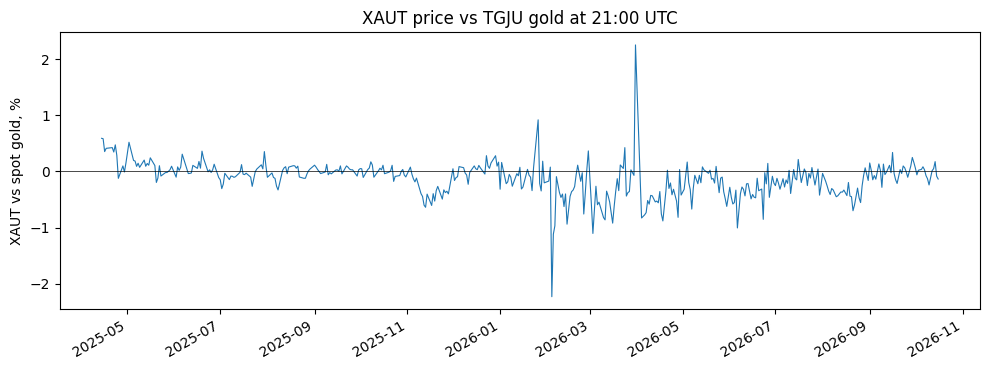

In [4]:
x = spot["open"][spot.index.hour == BEST]
x.index = x.index.normalize()
j = pd.concat({"xaut": x, "ons": ons}, axis=1).dropna()["2025-04-12":]
gap = (j["xaut"] / j["ons"] - 1) * 100
print(f"{len(gap)} days: mean {gap.mean():+.3f}%, std {gap.std():.3f}%, 1%-99% range [{gap.quantile(.01):+.2f}%, {gap.quantile(.99):+.2f}%], worst {gap.abs().max():.2f}% on {gap.abs().idxmax().date()}")
fig, ax = plt.subplots(figsize=(10, 3.8))
gap.plot(ax=ax, lw=0.8); ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("XAUT vs spot gold, %"); ax.set_xlabel("")
ax.set_title(f"XAUT price vs TGJU gold at {BEST}:00 UTC")
plt.tight_layout(); plt.savefig(ROOT / "images" / "xaut-gap.png", dpi=130); plt.show()

- XAUT به‌طور میانگین **۰٫۱۳۵٪ پایین‌تر** از قیمت TGJU است و انحراف معیار فاصله ۰٫۳۲٪ است. در ۹۸٪ روزها فاصله بین ۰٫۹۶٪- و ۰٫۵۱٪+ است.
- بدترین روز ۲۰۲۶-۰۳-۳۱ با ۲٫۲۶٪ بود. در آن روز قیمت TGJU (۴٬۵۴۳) ظاهراً مال ساعتی زودتر است و XAUT در ۲۱:۰۰ حدود ۴٬۶۴۶ بود. علتش را نمی‌دانیم.
- حدود ۰٫۱۳٪ اختلاف میانگین را نمی‌توانیم به XAUT نسبت بدهیم: ممکن است از ساعت واقعی ثبت TGJU یا هزینه کارمزد و هزینه نگهداری توکن باشد. بررسی نکرده‌ایم.

### در برابر آتی COMEX، ساعتی

آتی با spot فرق دارد (هزینه نگهداری)، پس **سطح** قیمت را مقایسه نمی‌کنیم. بازده ساعتی را مقایسه می‌کنیم، فقط ساعت‌هایی که هر دو بازارند:

In [5]:
j2 = pd.concat({"xaut": spot["close"], "gc": gc["close"]}, axis=1).dropna()
lvl = j2["xaut"] / j2["gc"] - 1
r2 = np.log(j2).diff().dropna()
r2 = r2[j2.index.to_series().diff().dt.total_seconds().reindex(r2.index) == 3600]   # consecutive hours only
print(f"level gap XAUT/GC-1: mean {lvl.mean():+.2%}  (mostly the futures premium, and it changes with the contract month)")
print("monthly mean gap, %:", (lvl.groupby(lvl.index.to_period('M')).mean() * 100).round(2).to_dict())
print(f"\nhourly return correlation: {r2['xaut'].corr(r2['gc']):.3f}  ({len(r2)} hours)")
print(f"annualised vol: XAUT {r2['xaut'].std() * np.sqrt(8760):.1%}, GC {r2['gc'].std() * np.sqrt(8760):.1%}")

level gap XAUT/GC-1: mean -0.65%  (mostly the futures premium, and it changes with the contract month)
monthly mean gap, %: {Period('2025-04', 'M'): 0.05, Period('2025-05', 'M'): -0.05, Period('2025-06', 'M'): -0.47, Period('2025-07', 'M'): -0.39, Period('2025-08', 'M'): -1.57, Period('2025-09', 'M'): -1.04, Period('2025-10', 'M'): -0.4, Period('2025-11', 'M'): -0.52, Period('2025-12', 'M'): -0.64, Period('2026-01', 'M'): -0.16, Period('2026-02', 'M'): -0.77, Period('2026-03', 'M'): -0.58, Period('2026-04', 'M'): -0.85, Period('2026-05', 'M'): -0.35, Period('2026-06', 'M'): -0.79, Period('2026-07', 'M'): -0.43, Period('2026-08', 'M'): -1.62, Period('2026-09', 'M'): -0.9, Period('2026-10', 'M'): -0.61}

hourly return correlation: 0.971  (8334 hours)
annualised vol: XAUT 29.0%, GC 30.9%


- همبستگی بازده ساعتی XAUT با آتی **۰٫۹۷۱** است و نوسان سالانه هر دو نزدیک است (۲۹٪ و ۳۱٪). یعنی جهت و اندازه حرکت‌ها تقریباً یکی است.
- **سطح** قیمت XAUT به‌طور میانگین ۰٫۶۵٪ پایین‌تر از آتی است، ولی این عدد ماه‌به‌ماه از ۰٫۰۵٪+ (آوریل ۲۰۲۵) تا ۱٫۶۲٪- (اوت ۲۰۲۶) تغییر می‌کند. به همین دلیل از فاصله سطح نتیجه نمی‌گیریم: آتی هزینه نگهداری دارد و با تعویض قرارداد پرش می‌کند. دقیقاً کدام بخش از این فاصله از آتی است و کدام از XAUT را جدا نکرده‌ایم.

## ۳. آخر هفته

بازار آتی طلا از جمعه عصر تا یکشنبه شب بسته است ولی XAUT ۲۴/۷ معامله می‌شود. پس حرکت XAUT در آخر هفته چقدر از «شکاف» بازگشایی دوشنبه خبر می‌دهد؟ برای هر آخر هفته: حرکت XAUT از بسته‌شدن آخرین کندل جمعه تا باز شدن اولین کندل بعد از بازگشایی، در برابر شکاف آتی در همان بازه.

79 closures; corr 0.70, R2 0.48, slope 0.81
same sign in 62% of closures; |gap| > 0.5% in 25 of them
std of the weekend move: XAUT 0.56%, futures gap 0.66%


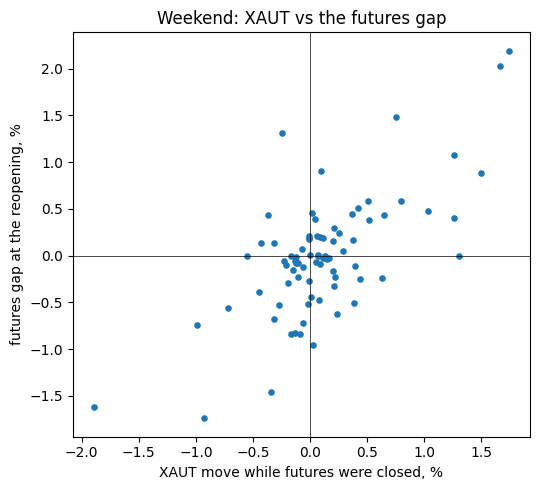

In [6]:
t = gc.index.to_series()
rows = []
for t1 in t[t.diff() > pd.Timedelta(hours=40)].index:      # first bar after a weekend/holiday closure
    i = gc.index.get_loc(t1)
    t0 = gc.index[i - 1]
    if t0 in spot.index and t1 in spot.index:
        rows.append({"close": t0, "reopen": t1,
                     "xaut_move": np.log(spot["open"][t1] / spot["close"][t0]),
                     "gc_gap": np.log(gc["open"].iloc[i] / gc["close"].iloc[i - 1])})
w = pd.DataFrame(rows)
slope = np.polyfit(w["xaut_move"], w["gc_gap"], 1)[0]
print(f"{len(w)} closures; corr {w['xaut_move'].corr(w['gc_gap']):.2f}, R2 {w['xaut_move'].corr(w['gc_gap']) ** 2:.2f}, slope {slope:.2f}")
print(f"same sign in {(np.sign(w['xaut_move']) == np.sign(w['gc_gap'])).mean():.0%} of closures; |gap| > 0.5% in {(w['gc_gap'].abs() > .005).sum()} of them")
print(f"std of the weekend move: XAUT {w['xaut_move'].std():.2%}, futures gap {w['gc_gap'].std():.2%}")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(w["xaut_move"] * 100, w["gc_gap"] * 100, s=14)
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set_xlabel("XAUT move while futures were closed, %"); ax.set_ylabel("futures gap at the reopening, %")
ax.set_title("Weekend: XAUT vs the futures gap")
plt.tight_layout(); plt.savefig(ROOT / "images" / "xaut-weekend.png", dpi=130); plt.show()

- **۷۹ بسته‌شدن** بازار آتی (آخر هفته‌ها و بعضی تعطیلی‌های بلند).
- همبستگی حرکت XAUT با شکاف آتی **۰٫۷۰** است (R² حدود ۰٫۴۸) و شیب ۰٫۸۱. یعنی حرکت آخر هفته XAUT حدود نیمی از تغییرات شکاف را توضیح می‌دهد.
- ولی **جهت** در ۶۲٪ موارد یکی است، یعنی در ۳۸٪ موارد XAUT جهت اشتباه را نشان داده. در ۲۵ مورد شکاف از ۰٫۵٪ بیشتر بوده.
- این یک توصیف است، نه سیگنال: هزینه معامله و ریسک نگهداری آخر هفته را نسنجیده‌ایم.

## ۴. پایه (Basis) دائمی در برابر اسپات

In [7]:
jb = pd.concat({"spot": spot["close"], "perp": perp["close"]}, axis=1).dropna()
basis = (jb["perp"] / jb["spot"] - 1) * 100
print(f"{len(basis)} hours: mean {basis.mean():+.4f}%, std {basis.std():.3f}%, 1%-99% [{basis.quantile(.01):+.3f}%, {basis.quantile(.99):+.3f}%]")
print(f"hours with |basis| > 0.2%: {(basis.abs() > .2).mean():.1%}")

13305 hours: mean -0.0391%, std 0.034%, 1%-99% [-0.124%, +0.056%]
hours with |basis| > 0.2%: 0.3%


قرارداد دائمی به‌طور میانگین **۰٫۰۳۹٪ پایین‌تر** از اسپات است و فاصله‌اش بسیار کوچک و پایدار (انحراف معیار ۰٫۰۳۴٪). فقط ۰٫۳٪ ساعت‌ها فاصله بیشتر از ۰٫۲٪ بوده. یعنی مکانیزم فاندینگ قیمت دائمی را خیلی نزدیک اسپات نگه می‌دارد.

## ۵. نرخ فاندینگ

در قرارداد دائمی، نرخ فاندینگ بین خریدارها و فروشنده‌ها هر ۴ ساعت پرداخت می‌شود تا قیمت قرارداد به اسپات نزدیک بماند. وقتی مثبت است، **خریدار** (long) به فروشنده (short) می‌پردازد.

3375 settlements: mean +4.64% per year, median +10.95%
share of settlements with a positive rate: 78%
range per settlement: -0.1217% .. +0.0525%
annualised mean by quarter, %: {Period('2025Q2', 'Q-DEC'): 2.38, Period('2025Q3', 'Q-DEC'): 5.27, Period('2025Q4', 'Q-DEC'): 4.55, Period('2026Q1', 'Q-DEC'): 6.07, Period('2026Q2', 'Q-DEC'): 4.4, Period('2026Q3', 'Q-DEC'): 4.9, Period('2026Q4', 'Q-DEC'): 5.81}


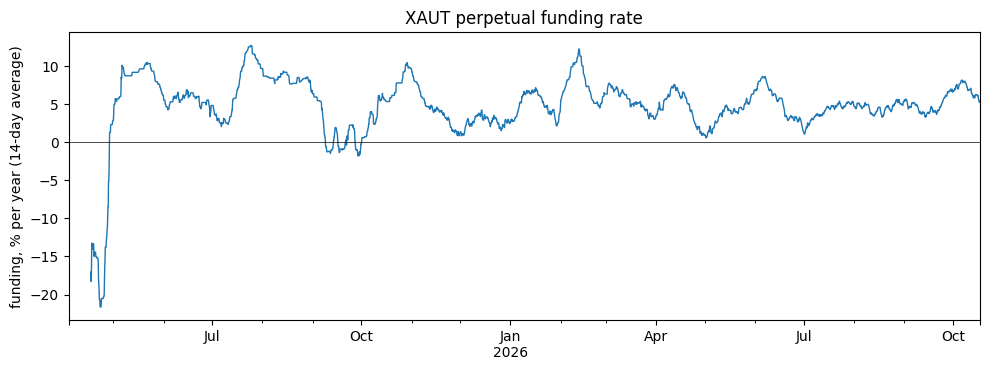

In [8]:
per_year = 6 * 365      # 4-hour settlements
print(f"{len(funding)} settlements: mean {funding.mean() * per_year:+.2%} per year, median {funding.median() * per_year:+.2%}")
print(f"share of settlements with a positive rate: {(funding > 0).mean():.0%}")
print(f"range per settlement: {funding.min():+.4%} .. {funding.max():+.4%}")
q = (funding.groupby(funding.index.to_period('Q')).mean() * per_year * 100).round(2)
print("annualised mean by quarter, %:", q.to_dict())
fig, ax = plt.subplots(figsize=(10, 3.8))
(funding.rolling(6 * 14).mean() * per_year * 100).plot(ax=ax, lw=1)
ax.axhline(0, color="k", lw=0.5); ax.set_ylabel("funding, % per year (14-day average)"); ax.set_xlabel("")
ax.set_title("XAUT perpetual funding rate")
plt.tight_layout(); plt.savefig(ROOT / "images" / "xaut-funding.png", dpi=130); plt.show()

- میانگین فاندینگ **۴٫۶۴٪ در سال** است (مثبت: خریدار می‌پردازد). ۷۸٪ پرداخت‌ها مثبت است.
- میانه دقیقاً ۱۰٫۹۵٪ در سال است. ۵۵٪ پرداخت‌ها دقیقاً ۰٫۰۰۵٪ در هر ۴ ساعت بوده؛ احتمالاً یک سطح پایه قرارداد است، ولی قاعده‌اش را بررسی نکرده‌ایم. ۲۲٪ منفی بوده‌اند و همین میانگین را پایین آورده.
- بازه هر پرداخت: ۰٫۱۲۲٪- تا ۰٫۰۵۲٪+. میانگین فصلی بین ۲٫۴٪ و ۶٫۱٪ در سال است.
- ایده «اسپات XAUT + فروش دائمی» (درس ۲۳ Quant Developer) از همین فاندینگ می‌آید. این‌جا آن را نیازموده‌ایم و کارمزد و ریسک طرف مقابل را حساب نکرده‌ایم.

## محدودیت‌ها

۱. **فقط حدود ۱۸ ماه** داده (از آوریل ۲۰۲۵). نمی‌دانیم در بحران‌های بلندتر چه می‌شد.
۲. **یک صرافی (Bybit)** و **یک توکن (XAUT).** PAXG در Bybit نیست و صرافی‌های دیگر را نسنجیده‌ایم.
۳. **مرجع قیمت:** اونس TGJU روزانه و غیررسمی است و ساعتش را از روی داده حدس زدیم؛ آتی با spot فرق دارد.
۴. **نقدشوندگی:** در روزهای کم‌معامله فاصله‌ها می‌توانند بزرگ‌تر از این میانگین‌ها باشند.
۵. **ریسک صادرکننده و حفاظت طلا:** این پست به آن نمی‌پردازد.

## جمع‌بندی

- XAUT قیمت طلا را **بسیار نزدیک** دنبال می‌کند: همبستگی بازده ساعتی ۰٫۹۷۱ با آتی، و فاصله روزانه با TGJU حدود ۰٫۱۳٪ پایین‌تر با انحراف معیار ۰٫۳۲٪ (در هم‌ترازترین ساعت).
- **ساعت ثبت قیمت** برای هر مقایسه حیاتی است: همبستگی بازده روزانه با TGJU از ۰٫۱ تا ۰٫۹۸ بسته به ساعت عوض می‌شود.
- در آخر هفته XAUT اطلاع جزئی از شکاف دوشنبه می‌دهد (همبستگی ۰٫۷۰) ولی جهت را در ۳۸٪ موارد اشتباه می‌گوید.
- قرارداد دائمی بسیار نزدیک اسپات است (۰٫۰۴٪ پایین‌تر) و فاندینگ میانگین حدود ۴٫۶٪ در سال بوده.

**گام بعدی:** بک‌تست صادقانه یک استراتژی روند روی طلا.